<a href="https://colab.research.google.com/github/costpetrides/Box_Model/blob/main/Plots.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

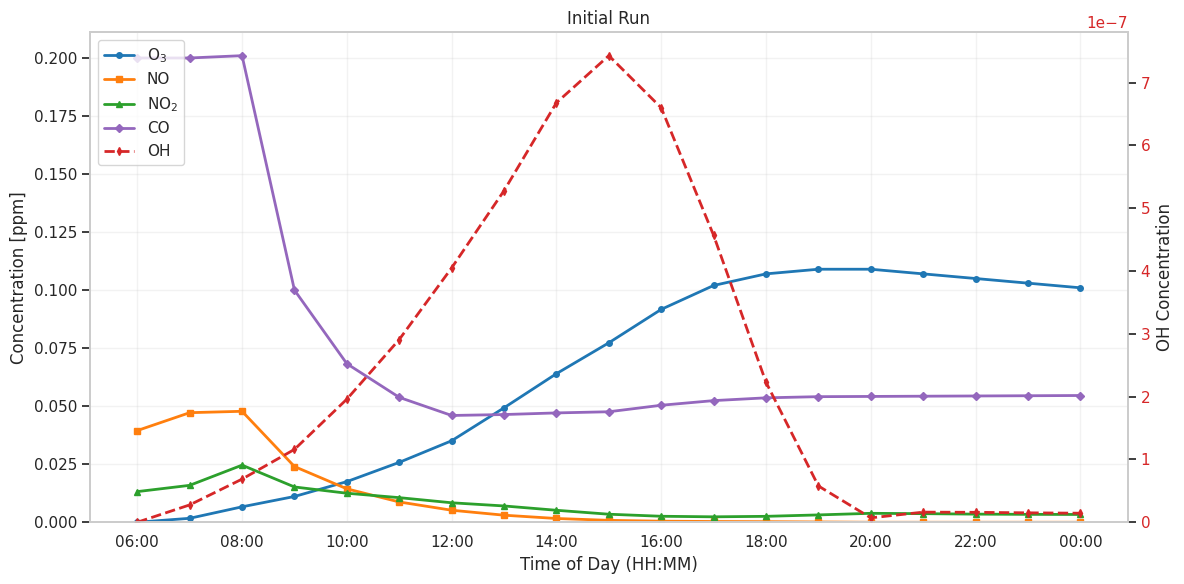

In [3]:

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, FuncFormatter

url = "https://raw.githubusercontent.com/costpetrides/Box_Model/refs/heads/main/TESTout1-Table%201.csv"
df = pd.read_csv(url, sep=";", decimal=",")
df.columns = df.columns.str.strip()

time = df["Time"] / 60
species = {
    "O3":  (r"O$_3$", "tab:blue", "o"),
    "NO":  ("NO",      "tab:orange", "s"),
    "NO2": (r"NO$_2$", "tab:green", "^"),
    "CO":  ("CO",      "tab:purple", "D"),
}

fig, ax = plt.subplots(figsize=(12, 6))
step = max(1, len(df) // 20)


for name, (label, color, marker) in species.items():
    ax.plot(time, df[name], label=label, color=color,
            lw=2, marker=marker, markevery=step, ms=4)


ax2 = ax.twinx()
ax2.plot(time, df["OH"], label="OH", color="tab:red",
         lw=2, ls="--", marker="d", markevery=step, ms=4)


def hhmm(x, pos):
    h, m = divmod(round(x * 60), 60)
    return f"{h % 24:02d}:{m:02d}"

ax.xaxis.set_major_locator(MultipleLocator(2))
ax.xaxis.set_major_formatter(FuncFormatter(hhmm))


ax.set(xlabel="Time of Day (HH:MM)",
       ylabel="Concentration [ppm]",
       title="Initial Run",
       ylim=(0, None))

ax2.set(ylabel="OH Concentration", ylim=(0, None))
ax2.tick_params(axis="y", labelcolor="tab:red")

ax.grid(alpha=0.25)
ax2.grid(False)

lines = ax.get_lines() + ax2.get_lines()
ax.legend(lines, [line.get_label() for line in lines],
          loc="upper left", frameon=True)

fig.tight_layout()
fig.savefig("box_model_dual_axis_plot.png", dpi=300)
plt.show()